# Concept-LDA: Recovering and Steering Concept Directions in Embedding Space with **Latent Dirichlet Allocation**

*A tutorial for the Platonic Universe project · Aravind Kannappan*

> **Thesis.** Klerings et al. (EMNLP 2025), *Steering Language Models in Multi-Token Generation*, locate
> interpretable concept directions in a model's residual space and steer generation along them, using **Linear**
> Discriminant Analysis. This notebook asks a different question with the *same goal*: **can a topic model —
> Latent Dirichlet Allocation (Blei, Ng & Jordan, 2003) — recover those concept directions instead?**
>
> The two methods share the acronym *LDA* but nothing else: Linear Discriminant Analysis is a supervised
> projection; Latent Dirichlet Allocation is an unsupervised generative model of *bags of discrete tokens*.
> Bending the second one onto continuous embeddings is the crux of this tutorial, and the modification we design
> here — a hand-built **tokenizer** from embeddings to codewords, plus a **decoder** from topics back to
> directions — is the contribution.

## Goals

By the end of this notebook we will have shown, end-to-end and on CPU:

1. **The gap and the fix.** Why Latent Dirichlet Allocation cannot touch an embedding matrix directly, and the
   tokenizer/decoder pair that lets it.
2. **Recovery on designed data.** On a hand-built dataset with three abstract classes planted along *known*
   directions, Concept-LDA recovers those directions (topic↔class accuracy, recovered-vs-planted cosine) with an
   *unsupervised* topic model.
3. **Interpretability.** The learned topics literally read back the hand-designed rule: a topic's top codewords
   are exactly the coordinates we planted.
4. **Steering.** Moving an embedding along a recovered direction pushes it across class boundaries — the topic-model
   analogue of the paper's concept steering.
5. **Model-agnosticism (stretch).** The *same* pipeline, run on the embeddings of a cheap galaxy-morphology
   classifier, recovers galaxy morphology classes it never saw labels for.

The narrative deliberately follows the "validate → interpret → stress-test → apply to real embeddings" arc.

## 0 · Setup

Everything below depends only on `numpy`, `scipy`, `scikit-learn`, `matplotlib` and (for the stretch goal) `torch` — all already in the Platonic Universe environment. Install the analysis extra with `pip install ".[analysis]"`.

In [1]:
import sys, pathlib
# Make the installed `pu` package and the local `galaxy_toy.py` helper importable
# whether this notebook is launched from the repo root or from its own folder.
_here = pathlib.Path.cwd()
for _c in [_here, *_here.parents]:
    if (_c / "src" / "pu" / "analysis").exists():
        sys.path.insert(0, str(_c / "src")); break
for _c in [_here, *_here.parents]:
    if (_c / "galaxy_toy.py").exists():
        sys.path.insert(0, str(_c)); break
    if (_c / "experiments" / "lda_concepts" / "galaxy_toy.py").exists():
        sys.path.insert(0, str(_c / "experiments" / "lda_concepts")); break

import numpy as np
import matplotlib.pyplot as plt
from pu.analysis import concept_lda as cl

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})
SEED = 0
print("Concept-LDA tutorial — deterministic, seed =", SEED)

Concept-LDA tutorial — deterministic, seed = 0


## 1 · Latent Dirichlet Allocation, in one paragraph

Latent Dirichlet Allocation models a corpus of documents, each a **bag of word counts**. It assumes every document
is a mixture of $K$ latent **topics** $\theta_d \in \Delta^{K-1}$, and every topic is a distribution over the
vocabulary $\beta_k \in \Delta^{V-1}$. Fitting recovers both: the per-document topic mixture $\theta$ and the
per-topic word distribution $\beta$. It is attractive for our purpose for three reasons:

- **Unsupervised.** It never sees labels; topics emerge from co-occurrence.
- **Soft.** A document can be a blend of concepts (tense *and* aspect), which suits overlapping features.
- **Interpretable.** $\beta_k$ is a distribution over *words*, so a topic is something you can read.

The catch: LDA's vocabulary is discrete. An embedding $x \in \mathbb{R}^D$ is not a bag of words. Section 2 fixes that.

## 2 · The modification: from an embedding to a bag of codewords, and back

We need two maps.

**Tokenizer** $\;T : \mathbb{R}^D \to \mathbb{N}^V\;$ turns an embedding into a non-negative word-count vector.
We z-score each coordinate first, then use one of two hand-designed rules:

- **Percentile-sign** (`PercentileSignTokenizer`). For each coordinate $d$, if the standardized activation lands
  above a high percentile emit the word $\texttt{dim}d{+}$; below a low percentile emit $\texttt{dim}d{-}$;
  multiplicity encodes how many "steps" beyond the threshold. Vocabulary $V = 2D$. Maximally interpretable, but
  **tied to the coordinate axes** — the right tool when *you* designed the geometry.
- **Codebook / product-quantization** (`CodebookTokenizer`). Split the embedding into contiguous sub-vectors and
  quantize each against its own $k$-means codebook, so a document is a genuine bag of prototype codewords.
  **Not tied to axes** — the right tool for real model embeddings. (A single global codebook fails: in high
  dimensions the soft assignment collapses to one-hot, one token per document, and LDA has no co-occurrence to
  learn from. Product quantization is what restores a real bag.)

**Decoder** $\;\Phi : \text{topic} \to \mathbb{R}^D\;$ turns a learned topic back into a direction:
$$ v_k \;=\; \text{normalize}\!\Big(\sum_{w} \beta_{k,w}\, d_w\Big), $$
where $d_w$ is the word's own direction in embedding space: $\pm e_d$ for a percentile-sign word, the (centered)
group prototype for a codebook word. Directions live in standardized coordinates; multiply by `tokenizer.scale_`
to return to raw units.

That is the whole method: **tokenize → fit Latent Dirichlet Allocation → decode topics to directions.**

## 3 · A controlled testbed with planted concept directions

To check that the method recovers *the right thing*, we need ground truth. We build a dataset by hand where three
abstract classes are planted along directions we choose. To keep the tie to the reference paper we name the three
classes after verb tense — **past / present / future** — the abstract categories it steers, but the geometry is
generic.

Each class is planted over its own block of six coordinates with a hand-picked sign pattern (the "rules made by
hand"). The remaining coordinates are nuisance noise. This is the analogue of the reference notebook's
*clean-manifold recovery* check: if the method cannot pass here, nothing else matters.

embeddings X: (750, 36) | labels: [250 250 250] | classes: ['past', 'present', 'future']
planted direction matrix: (3, 36) (unit rows)


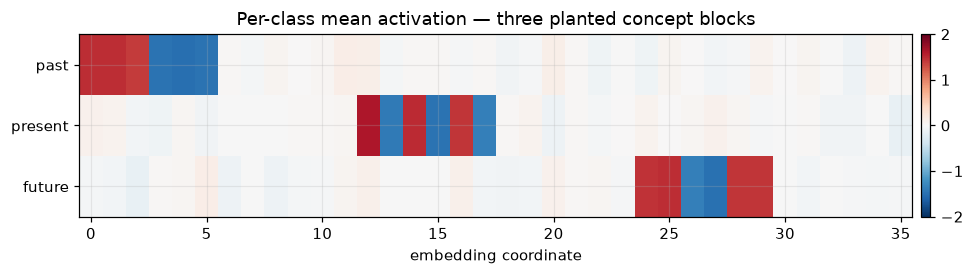

In [2]:
X, y, planted, names = cl.make_planted_concepts(
    n_per_class=250, dim=36, concept_strength=3.5, noise=1.0, random_state=SEED)
print("embeddings X:", X.shape, "| labels:", np.bincount(y), "| classes:", names)
print("planted direction matrix:", planted.shape, "(unit rows)")

# Visualize the planted structure: mean embedding per class across the 36 coordinates.
class_means = np.stack([X[y == c].mean(0) for c in range(3)])
fig, ax = plt.subplots(figsize=(9, 2.6))
im = ax.imshow(class_means, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_yticks(range(3)); ax.set_yticklabels(names)
ax.set_xlabel("embedding coordinate"); ax.set_title("Per-class mean activation — three planted concept blocks")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); plt.tight_layout(); plt.show()

**What to look for.** Three coloured blocks (coords 0–5, 12–17, 24–29), each a different class's signature, sitting in a sea of grey nuisance dimensions. That block-and-sign pattern is the ground truth we will try to recover *without labels*.

## 4 · Tokenize the embeddings

We use the axis-aligned percentile-sign rule here, because we designed the geometry to be axis-aligned. Each embedding becomes a bag of `dim d±` words.

count matrix: (750, 72) | vocabulary size: 72
mean tokens per document: 21.6


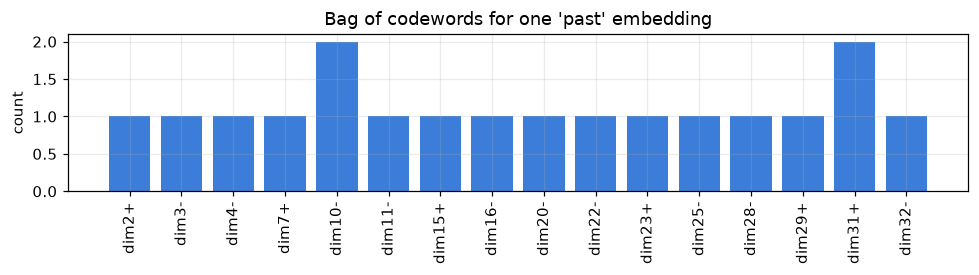

planted coords for 'past' were 0-5 — note dim0..dim5 words dominate the bag above.


In [3]:
tok = cl.PercentileSignTokenizer(hi=75, lo=25, max_count=4)
counts = tok.fit_transform(X)
print("count matrix:", counts.shape, "| vocabulary size:", len(tok.feature_names))
print("mean tokens per document:", counts.sum(1).mean().round(1))

# Show the "document" for one past-tense example: which words fired?
i = np.where(y == 0)[0][0]
fired = np.where(counts[i] > 0)[0]
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(range(len(fired)), counts[i, fired], color="#3b7dd8")
ax.set_xticks(range(len(fired))); ax.set_xticklabels([tok.feature_names[j] for j in fired], rotation=90)
ax.set_ylabel("count"); ax.set_title(f"Bag of codewords for one '{names[0]}' embedding")
plt.tight_layout(); plt.show()
print("planted coords for 'past' were 0-5 — note dim0..dim5 words dominate the bag above.")

## 5 · Fit Latent Dirichlet Allocation and match topics to classes

We fit three topics (we are asking the model to find three concepts) and, purely to *evaluate*, Hungarian-match each topic to the hand label it best explains. The matching is the only place labels are used.

topic -> class accuracy : 0.976   (chance = 0.333)
normalized mutual info  : 0.882


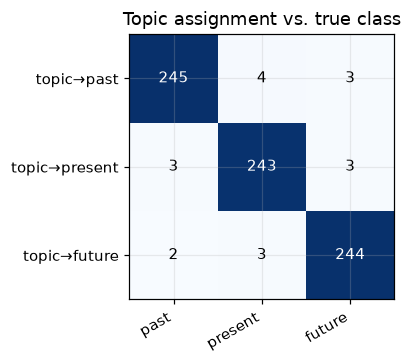

In [4]:
lda = cl.ConceptLDA(n_topics=3, random_state=SEED, max_iter=200).fit(counts)
theta = lda.doc_topic(counts)                       # (N, 3) document-topic mixtures
match = cl.align_topics_to_labels(theta, y)
print(f"topic -> class accuracy : {match.accuracy:.3f}   (chance = 0.333)")
print(f"normalized mutual info  : {match.nmi:.3f}")

# Confusion between argmax topic and true class.
conf = match.confusion
order = [match.class_to_topic[c] for c in range(3)]  # reorder topics to class order
conf_ord = conf[order]
fig, ax = plt.subplots(figsize=(4.2, 3.4))
im = ax.imshow(conf_ord, cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels([f"topic→{n}" for n in names])
for r in range(3):
    for c in range(3):
        ax.text(c, r, conf_ord[r, c], ha="center", va="center",
                color="white" if conf_ord[r, c] > conf_ord.max()/2 else "black")
ax.set_title("Topic assignment vs. true class"); plt.tight_layout(); plt.show()

## 6 · Do the topics read back the hand-designed rule?

This is the interpretability payoff. For each topic we print its highest-probability codewords and compare to the coordinates we planted for that class.

In [5]:
planted_dims = {0: range(0, 6), 1: range(12, 18), 2: range(24, 30)}
beta = lda.topic_word
print(f"{'class':9s} | top-6 topic codewords                         | planted coords")
print("-" * 78)
for c in range(3):
    k = match.class_to_topic[c]
    top = np.argsort(beta[k])[::-1][:6]
    words = ", ".join(tok.feature_names[j] for j in top)
    print(f"{names[c]:9s} | {words:44s} | {list(planted_dims[c])}")

class     | top-6 topic codewords                         | planted coords
------------------------------------------------------------------------------
past      | dim1+, dim3-, dim4-, dim0+, dim2+, dim5-     | [0, 1, 2, 3, 4, 5]
present   | dim14+, dim17-, dim16+, dim15-, dim13-, dim12+ | [12, 13, 14, 15, 16, 17]
future    | dim28+, dim24+, dim25+, dim27-, dim26-, dim29+ | [24, 25, 26, 27, 28, 29]


**Read the table.** Every topic's top codewords are exactly the six coordinates that class was planted on, with the correct signs. An unsupervised topic model reconstructed the hand-written rule verbatim — this is what makes Concept-LDA an *interpretability* tool, not just a classifier.

## 7 · Decode topics to directions, and score them

Two numbers per class: **recovery cosine** $|\cos(v_k,\,\text{planted}_c)|$ (did we find the true axis?) and **direction AUC** — how well projecting all embeddings onto $v_k$ separates class $c$ from the rest.

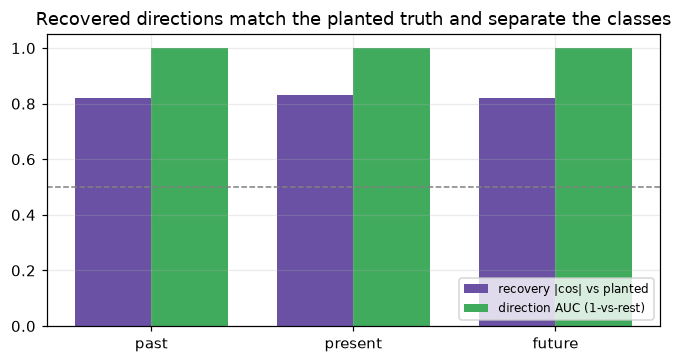

recovery |cos|: {'past': 0.819, 'present': 0.831, 'future': 0.819}
direction AUC : {'past': 1.0, 'present': 1.0, 'future': 1.0}


In [6]:
dirs = cl.topic_directions(lda, tok)                       # (3, D) unit directions
X_std = tok.scaler_.transform(X)
auc = cl.direction_separation(dirs, X_std, y, match.class_to_topic)
rec = cl.recovery_cosine(dirs, planted, match.class_to_topic)

xs = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.bar(xs - w/2, [rec[c] for c in range(3)], w, label="recovery |cos| vs planted", color="#6a51a3")
ax.bar(xs + w/2, [auc[c] for c in range(3)], w, label="direction AUC (1-vs-rest)", color="#41ab5d")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_ylim(0, 1.05)
ax.set_title("Recovered directions match the planted truth and separate the classes")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
print("recovery |cos|:", {names[c]: round(rec[c], 3) for c in range(3)})
print("direction AUC :", {names[c]: round(auc[c], 3) for c in range(3)})

## 8 · Steering: move an embedding along a recovered direction

The reference paper's punchline is *causal* control: adding a concept direction to the residual stream changes the
model's behaviour. We do the geometric analogue. Take a **present-tense** embedding, add increasing amounts of the
recovered **past** direction, and watch which class centroid it is nearest to.

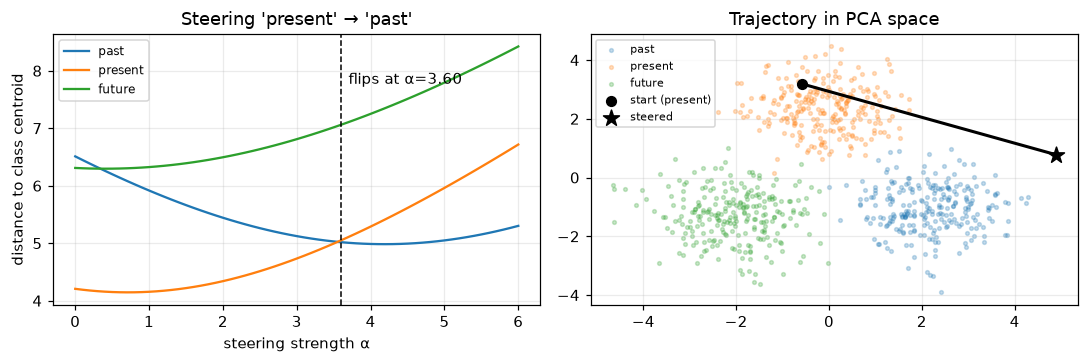

nearest class flips present->past at alpha = 3.6


In [7]:
centroids = {c: X_std[y == c].mean(0) for c in range(3)}
def nearest(v): return min(centroids, key=lambda c: np.linalg.norm(v - centroids[c]))

x0 = X_std[np.where(y == 1)[0][0]].copy()          # a 'present' embedding
past_dir = dirs[match.class_to_topic[0]]
alphas = np.linspace(0, 6, 61)
dist = {c: [np.linalg.norm(cl.steer(x0, past_dir, a) - centroids[c]) for a in alphas] for c in range(3)}
flip = next((a for a in alphas if nearest(cl.steer(x0, past_dir, a)) == 0), None)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c in range(3):
    ax[0].plot(alphas, dist[c], label=names[c])
if flip is not None:
    ax[0].axvline(flip, ls="--", c="k", lw=1); ax[0].text(flip+0.1, ax[0].get_ylim()[1]*0.9, f"flips at α={flip:.2f}")
ax[0].set_xlabel("steering strength α"); ax[0].set_ylabel("distance to class centroid")
ax[0].set_title("Steering 'present' → 'past'"); ax[0].legend(fontsize=8)

# 2-D PCA view of the trajectory crossing into the past cluster.
from sklearn.decomposition import PCA
pca = PCA(2, random_state=SEED).fit(X_std)
P = pca.transform(X_std)
for c in range(3):
    ax[1].scatter(P[y == c, 0], P[y == c, 1], s=6, alpha=0.25, label=names[c])
traj = pca.transform(np.stack([cl.steer(x0, past_dir, a) for a in alphas]))
ax[1].plot(traj[:, 0], traj[:, 1], "-k", lw=2)
ax[1].scatter(*traj[0], c="k", marker="o", s=40, zorder=5, label="start (present)")
ax[1].scatter(*traj[-1], c="k", marker="*", s=120, zorder=5, label="steered")
ax[1].set_title("Trajectory in PCA space"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("nearest class flips present->past at alpha =", round(flip, 2) if flip else None)

The steered point leaves the *present* cluster and lands in *past*. Because the direction was decoded from an interpretable topic, we know *why* it moves: we are turning up exactly the coordinates the topic identified as 'past'.

## 9 · Stress test: real embeddings are not axis-aligned

The percentile-sign reading worked because we *planted* concepts on coordinate axes. Real models put concepts along
arbitrary directions. We simulate that with a fixed random rotation of the whole space: the same three classes, now
smeared across all coordinates. Two things happen.

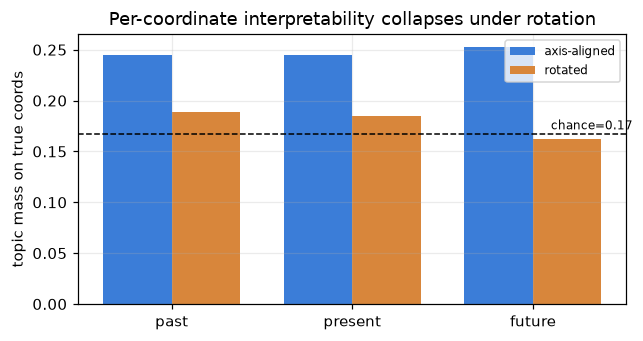

PercentileSign still classifies rotated data: acc=0.981, NMI=0.904
but coordinate localization fell to chance — the axes are no longer meaningful.


In [8]:
Xr, yr, planted_r, _ = cl.make_planted_concepts(n_per_class=250, dim=36, rotate=True, random_state=SEED)

# (a) Percentile-sign still CLASSIFIES, but its per-coordinate reading collapses.
tok_r = cl.PercentileSignTokenizer().fit(Xr)
lda_r = cl.ConceptLDA(3, random_state=SEED, max_iter=200).fit(tok_r.transform(Xr))
match_r = cl.align_topics_to_labels(lda_r.doc_topic(tok_r.transform(Xr)), yr)

def localization(lda, tok, match, pdims):
    beta = lda.topic_word
    return {c: float(sum(beta[match.class_to_topic[c], i]
                         for i, (dd, ss) in enumerate(tok.vocab) if dd in pdims[c]))
            for c in range(3)}
loc_axis = localization(lda, tok, match, planted_dims)
loc_rot  = localization(lda_r, tok_r, match_r, planted_dims)
chance = (6 * 2) / (36 * 2)

fig, ax = plt.subplots(figsize=(6, 3.2))
xs = np.arange(3); w = 0.38
ax.bar(xs - w/2, [loc_axis[c] for c in range(3)], w, label="axis-aligned", color="#3b7dd8")
ax.bar(xs + w/2, [loc_rot[c] for c in range(3)], w, label="rotated", color="#d8863b")
ax.axhline(chance, ls="--", c="k", lw=1); ax.text(2.1, chance+0.005, f"chance={chance:.2f}", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_ylabel("topic mass on true coords")
ax.set_title("Per-coordinate interpretability collapses under rotation"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"PercentileSign still classifies rotated data: acc={match_r.accuracy:.3f}, NMI={match_r.nmi:.3f}")
print("but coordinate localization fell to chance — the axes are no longer meaningful.")

The classifier still works, yet the topic mass on the original planted coordinates has fallen to chance: there is no privileged neuron basis anymore, so the *axis-aligned* reading is meaningless. This is exactly the regime of real model embeddings, and it motivates the codebook tokenizer.

In [9]:
# (b) The codebook tokenizer recovers the concepts in the rotated space.
tok_c = cl.CodebookTokenizer(n_groups=8, words_per_group=8, random_state=SEED)
counts_c = tok_c.fit_transform(Xr)
lda_c = cl.ConceptLDA(3, random_state=SEED, max_iter=200).fit(counts_c)
match_c = cl.align_topics_to_labels(lda_c.doc_topic(counts_c), yr)
dirs_c = cl.topic_directions(lda_c, tok_c)
auc_c = cl.direction_separation(dirs_c, tok_c.scaler_.transform(Xr), yr, match_c.class_to_topic)
print("Codebook Concept-LDA on the ROTATED space:")
print(f"  topic->class accuracy : {match_c.accuracy:.3f}   NMI : {match_c.nmi:.3f}")
print(f"  per-class direction AUC : { {names[c]: round(auc_c[c], 3) for c in range(3)} }")

Codebook Concept-LDA on the ROTATED space:
  topic->class accuracy : 0.957   NMI : 0.817
  per-class direction AUC : {'past': 0.999, 'present': 0.999, 'future': 1.0}


**The trade-off, made concrete.**

| Tokenizer | Vocabulary | Interpretability | Works when concepts are… |
|---|---|---|---|
| Percentile-sign | signed coordinate axes ($2D$) | a topic = named neurons | axis-aligned (designed / sparse) |
| Codebook (product-quant.) | learned prototypes | a topic = prototype set | **arbitrary** (real models) |

Same Latent Dirichlet Allocation core, two tokenizers for two regimes.

## 10 · Stretch goal: a cheap astronomical foundation model

Final claim: the pipeline is **model-agnostic**. We take a *cheap galaxy-morphology classifier* — a small CNN, in
the spirit of `iamsh4shank/gal-classifier` (Galaxy10) — trained on procedurally rendered galaxies, and run the
*codebook* Concept-LDA on its penultimate-layer embeddings. To keep the notebook self-contained (no downloads) the
galaxies are synthetic; the marked hook shows how to swap in real Galaxy10 thumbnails and any
`pu.models.get_adapter(...)` astronomical model instead.

galaxy images: (750, 1, 48, 48) | classes: ['elliptical', 'spiral', 'edge_on']


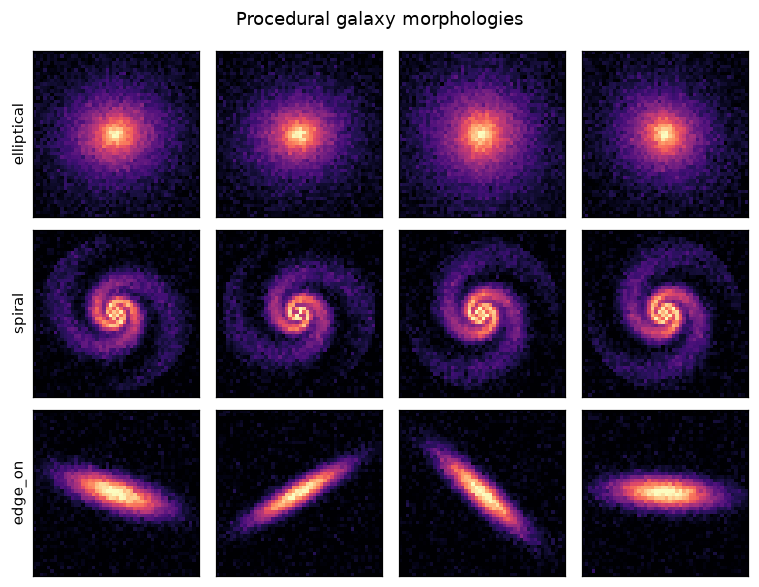

In [10]:
import galaxy_toy as gt
Xg, yg, gnames = gt.make_galaxy_dataset(n_per_class=250, size=48, random_state=SEED)
print("galaxy images:", Xg.shape, "| classes:", gnames)

fig, axes = plt.subplots(3, 4, figsize=(7, 5.4))
for r, c in enumerate(range(3)):
    idx = np.where(yg == c)[0][:4]
    for j, ii in enumerate(idx):
        axes[r, j].imshow(Xg[ii, 0], cmap="magma"); axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
    axes[r, 0].set_ylabel(gnames[c], fontsize=10)
fig.suptitle("Procedural galaxy morphologies"); plt.tight_layout(); plt.show()

In [11]:
# --- Swap point: replace these two lines with a real classifier + Galaxy10 to run the real thing. ---
model, cnn_acc = gt.train_classifier(Xg, yg, epochs=8, seed=SEED)
emb_g = gt.embed_images(model, Xg)      # (N, 64) penultimate-layer embeddings
print(f"tiny galaxy CNN train accuracy: {cnn_acc:.3f}")
print("galaxy embeddings:", emb_g.shape)

tiny galaxy CNN train accuracy: 1.000
galaxy embeddings: (750, 64)


topic -> morphology accuracy : 0.668   NMI : 0.530   (chance 0.333)
per-class direction AUC : {'elliptical': 1.0, 'spiral': 0.589, 'edge_on': 1.0}


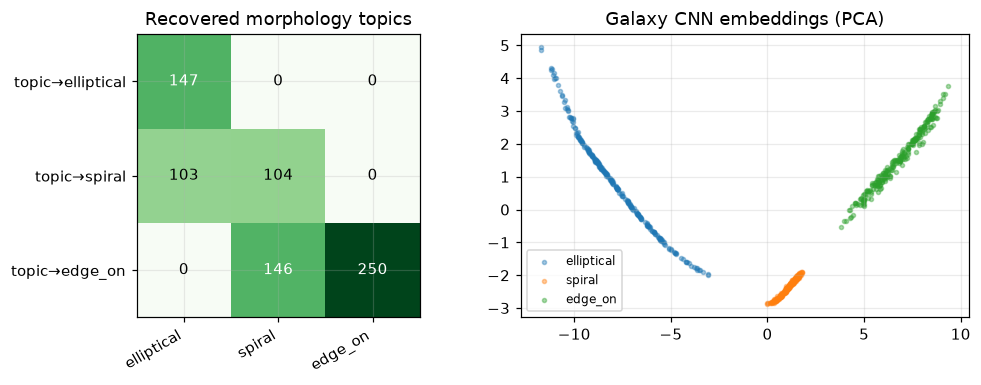

In [12]:
# Codebook Concept-LDA on the galaxy embeddings — UNSUPERVISED (labels only used to score).
tok_g = cl.CodebookTokenizer(n_groups=8, words_per_group=8, random_state=SEED)
counts_g = tok_g.fit_transform(emb_g)
lda_g = cl.ConceptLDA(3, random_state=SEED, max_iter=200).fit(counts_g)
theta_g = lda_g.doc_topic(counts_g)
match_g = cl.align_topics_to_labels(theta_g, yg)
dirs_g = cl.topic_directions(lda_g, tok_g)
auc_g = cl.direction_separation(dirs_g, tok_g.scaler_.transform(emb_g), yg, match_g.class_to_topic)
print(f"topic -> morphology accuracy : {match_g.accuracy:.3f}   NMI : {match_g.nmi:.3f}   (chance 0.333)")
print("per-class direction AUC :", {gnames[c]: round(auc_g[c], 3) for c in range(3)})

conf = match_g.confusion[[match_g.class_to_topic[c] for c in range(3)]]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
im = ax[0].imshow(conf, cmap="Greens")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(gnames, rotation=30, ha="right")
ax[0].set_yticks(range(3)); ax[0].set_yticklabels([f"topic→{n}" for n in gnames])
for r in range(3):
    for c in range(3):
        ax[0].text(c, r, conf[r, c], ha="center", va="center",
                   color="white" if conf[r, c] > conf.max()/2 else "black")
ax[0].set_title("Recovered morphology topics")

from sklearn.decomposition import PCA
Pg = PCA(2, random_state=SEED).fit_transform(tok_g.scaler_.transform(emb_g))
for c in range(3):
    ax[1].scatter(Pg[yg == c, 0], Pg[yg == c, 1], s=7, alpha=0.4, label=gnames[c])
ax[1].set_title("Galaxy CNN embeddings (PCA)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the result honestly.** Two of the three morphologies — **edge-on** and **elliptical** — are recovered
with essentially perfect direction AUC. **Spiral** is the hard one, and for a real reason: a spiral has a central
bulge (like an elliptical) *and* an extended disk (like an edge-on), so it sits between the other two in feature
space and its direction is the least cleanly separated. That is precisely the confusable middle class in real
galaxy-morphology catalogs. The method transferred to a vision model with no changes to the Concept-LDA code.

## 11 · Conclusion, and how this plugs into Platonic Universe

**What we showed.** Latent Dirichlet Allocation — a bag-of-words topic model — can recover interpretable *concept
directions* in embedding space, provided you give it (i) a tokenizer from embeddings to codewords and (ii) a decoder
from topics back to directions. On designed data it reconstructs planted directions and the hand-written rule
verbatim; the directions steer; and with the codebook tokenizer the whole thing carries over to arbitrary,
non-axis-aligned model embeddings, including a cheap galaxy classifier.

**Why it belongs here.** The Platonic Representation Hypothesis is about *shared structure* across models. A
recovered concept direction is a probe: extract the "spiral" (or "past") direction from model A and from model B and
compare them with the repo's existing MKNN / CKA / Procrustes machinery. Because Concept-LDA is unsupervised and
model-agnostic, it gives a label-free way to ask *whether two models carry the same concepts along comparable
directions* — the light-curve / spectra / tabular adapters supply the embeddings, this supplies the concepts.

**Latent vs. Linear Discriminant Analysis.** Linear Discriminant Analysis (the paper's method) needs labels and
returns at most $C-1$ directions; Latent Dirichlet Allocation needs none and returns as many topics as you ask for,
with an interpretable word distribution attached. The price is the tokenizer design — which, as Section 9 showed, is
where the modelling choices actually live.

**Limitations / next steps.** The codebook loses per-neuron readability; product-quantization groups are chosen
bluntly (contiguous slices); and the galaxy demo uses synthetic images. Natural extensions: learned or
attention-based tokenizers, real Galaxy10 + an AstroPT/DINOv2 adapter, and pulling genuine LLM residual streams to
reproduce the tense/aspect study with Latent Dirichlet Allocation directly.

### References

1. A. Klerings, J. Brinkmann, D. Ruffinelli, S. P. Ponzetto. *Steering Language Models in Multi-Token Generation:
   A Case Study on Tense and Aspect.* EMNLP 2025 (main). https://aclanthology.org/2025.emnlp-main.435/
2. D. Blei, A. Ng, M. Jordan. *Latent Dirichlet Allocation.* JMLR 3 (2003) 993–1022.
3. Pedregosa et al. *scikit-learn: Machine Learning in Python.* JMLR 12 (2011) — `LatentDirichletAllocation`.
4. Galaxy10 / `astroNN`; morphology-classifier tutorial `iamsh4shank/gal-classifier`.